# ARIMA/SARIMA - Identificação, ajuste e previsão

Processa as três séries com SARIMA, identifica ordens via ACF/PACF e grid search (AIC),
ajusta apenas no treino e prevê os 28 dias da validação.

## Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from itertools import product
import itertools

## Carregamento de dados

In [3]:
df_train = pd.read_csv("../../dados/treino.csv")
df_val = pd.read_csv("../../dados/validacao.csv")

df_train["date"] = pd.to_datetime(df_train["date"])
df_val["date"] = pd.to_datetime(df_val["date"])

series_names = ["store_total", "FOODS", "HOBBIES"]

print(f"Treino: {df_train['date'].min()} a {df_train['date'].max()} ({len(df_train)} dias)")
print(f"Validação: {df_val['date'].min()} a {df_val['date'].max()} ({len(df_val)} dias)")

Treino: 2011-01-29 00:00:00 a 2016-03-27 00:00:00 (1885 dias)
Validação: 2016-03-28 00:00:00 a 2016-04-24 00:00:00 (28 dias)


## Grid search para SARIMA

Busca as melhores ordens (p, d, q, P, D, Q) usando AIC no treino.

In [4]:
def find_best_sarima_order(serie, serie_name, m=7, max_p=2, max_d=1, max_q=2, max_P=1, max_D=1, max_Q=1):
    """
    Grid search para encontrar a melhor ordem SARIMA usando AIC.
    Limita a busca para ordens pequenas (computação rápida).
    """
    best_aic = np.inf
    best_order = None
    best_seasonal_order = None
    results_log = []
    
    p_range = range(0, max_p + 1)
    d_range = range(0, max_d + 1)
    q_range = range(0, max_q + 1)
    P_range = range(0, max_P + 1)
    D_range = range(0, max_D + 1)
    Q_range = range(0, max_Q + 1)
    
    total_combinations = len(list(p_range)) * len(list(d_range)) * len(list(q_range)) * \
                        len(list(P_range)) * len(list(D_range)) * len(list(Q_range))
    print(f"\n{serie_name}: testando {total_combinations} combinações...")
    
    count = 0
    for p, d, q, P, D, Q in itertools.product(p_range, d_range, q_range, P_range, D_range, Q_range):
        count += 1
        if count % 50 == 0:
            print(f"  Progresso: {count}/{total_combinations}")
        
        try:
            model = SARIMAX(
                serie,
                order=(p, d, q),
                seasonal_order=(P, D, Q, m),
                enforce_stationarity=False,
                enforce_invertibility=False
            )
            results = model.fit(disp=False, maxiter=200)
            aic = results.aic
            
            results_log.append({
                'order': (p, d, q),
                'seasonal_order': (P, D, Q, m),
                'aic': aic
            })
            
            if aic < best_aic:
                best_aic = aic
                best_order = (p, d, q)
                best_seasonal_order = (P, D, Q, m)
        except:
            continue
    
    # Exibe top 5 melhores ordens
    results_log_sorted = sorted(results_log, key=lambda x: x['aic'])
    print(f"\n  Top 5 melhores ordens:")
    for i, res in enumerate(results_log_sorted[:5], 1):
        print(f"    {i}. SARIMA{res['order']}{res['seasonal_order']}: AIC={res['aic']:.2f}")
    
    print(f"\n  ✓ Melhor ordem: SARIMA{best_order}{best_seasonal_order} com AIC={best_aic:.2f}")
    
    return best_order, best_seasonal_order

## Identificação de ordens

In [5]:
# Grid search para cada série
# Limita a p, q em {0, 1, 2} e P, Q em {0, 1} para rapidez
sarima_orders = {}

for serie_name in series_names:
    order, seasonal_order = find_best_sarima_order(
        df_train[serie_name].values,
        serie_name,
        m=7,
        max_p=2, max_d=1, max_q=2,
        max_P=1, max_D=1, max_Q=1
    )
    sarima_orders[serie_name] = (order, seasonal_order)


store_total: testando 144 combinações...
  Progresso: 50/144


/home/jaimewillian/Documentos/FGV/6P/Séries Temporais/Series-Temporais-G5/.env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


  Progresso: 100/144


/home/jaimewillian/Documentos/FGV/6P/Séries Temporais/Series-Temporais-G5/.env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/home/jaimewillian/Documentos/FGV/6P/Séries Temporais/Series-Temporais-G5/.env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



  Top 5 melhores ordens:
    1. SARIMA(1, 1, 2)(1, 1, 1, 7): AIC=27995.67
    2. SARIMA(2, 1, 2)(1, 1, 1, 7): AIC=27997.63
    3. SARIMA(2, 0, 2)(1, 1, 1, 7): AIC=28009.31
    4. SARIMA(1, 1, 1)(1, 1, 1, 7): AIC=28009.65
    5. SARIMA(2, 1, 1)(1, 1, 1, 7): AIC=28009.69

  ✓ Melhor ordem: SARIMA(1, 1, 2)(1, 1, 1, 7) com AIC=27995.67

FOODS: testando 144 combinações...
  Progresso: 50/144


/home/jaimewillian/Documentos/FGV/6P/Séries Temporais/Series-Temporais-G5/.env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


  Progresso: 100/144

  Top 5 melhores ordens:
    1. SARIMA(1, 1, 2)(1, 1, 1, 7): AIC=26908.67
    2. SARIMA(2, 1, 2)(1, 1, 1, 7): AIC=26911.45
    3. SARIMA(2, 0, 2)(1, 1, 1, 7): AIC=26920.78
    4. SARIMA(2, 1, 1)(1, 1, 1, 7): AIC=26922.33
    5. SARIMA(1, 1, 1)(1, 1, 1, 7): AIC=26924.42

  ✓ Melhor ordem: SARIMA(1, 1, 2)(1, 1, 1, 7) com AIC=26908.67

HOBBIES: testando 144 combinações...
  Progresso: 50/144
  Progresso: 100/144


/home/jaimewillian/Documentos/FGV/6P/Séries Temporais/Series-Temporais-G5/.env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



  Top 5 melhores ordens:
    1. SARIMA(1, 1, 2)(0, 1, 1, 7): AIC=21996.09
    2. SARIMA(2, 1, 2)(1, 1, 1, 7): AIC=21999.25
    3. SARIMA(2, 1, 2)(0, 1, 1, 7): AIC=22000.09
    4. SARIMA(0, 1, 2)(0, 1, 1, 7): AIC=22004.26
    5. SARIMA(2, 0, 2)(1, 1, 1, 7): AIC=22005.67

  ✓ Melhor ordem: SARIMA(1, 1, 2)(0, 1, 1, 7) com AIC=21996.09


## Ajuste dos modelos SARIMA no treino

In [6]:
# Ajusta o modelo final em cada série usando toda a série de treino
fitted_models = {}

for serie_name in series_names:
    order, seasonal_order = sarima_orders[serie_name]
    print(f"\nAjustando {serie_name}: SARIMA{order}{seasonal_order}...")
    
    model = SARIMAX(
        df_train[serie_name].values,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    
    results = model.fit(disp=False, maxiter=200)
    fitted_models[serie_name] = results
    
    print(f"  AIC: {results.aic:.2f}")
    print(f"  BIC: {results.bic:.2f}")


Ajustando store_total: SARIMA(1, 1, 2)(1, 1, 1, 7)...
  AIC: 27995.67
  BIC: 28028.86

Ajustando FOODS: SARIMA(1, 1, 2)(1, 1, 1, 7)...
  AIC: 26908.67
  BIC: 26941.86

Ajustando HOBBIES: SARIMA(1, 1, 2)(0, 1, 1, 7)...
  AIC: 21996.09
  BIC: 22023.75


## Previsão para o horizonte de validação (28 dias)

In [9]:
# Faz previsão para os 28 dias da validação
h = len(df_val)  # 28 dias
previsoes_sarima = {}

for serie_name in series_names:
    results = fitted_models[serie_name]
    # forecast: previsão puntual dos próximos h períodos
    forecast = results.get_forecast(steps=h).predicted_mean
    previsoes_sarima[serie_name] = forecast
    
    print(f"{serie_name}: min={forecast.min():.0f}, max={forecast.max():.0f}, mean={forecast.mean():.0f}")

store_total: min=3633, max=5625, mean=4374
FOODS: min=2418, max=3761, mean=2906
HOBBIES: min=434, max=617, mean=499


## Exportação das previsões no formato requerido

In [10]:
# Cria DataFrame no formato: date, series, modelo, yhat
predictions_list = []

for serie_name in series_names:
    for i, (date, yhat) in enumerate(zip(df_val["date"], previsoes_sarima[serie_name])):
        predictions_list.append({
            "date": date,
            "series": serie_name,
            "modelo": "sarima",
            "yhat": yhat
        })

df_previsoes = pd.DataFrame(predictions_list)
print(f"\nPrevisões SARIMA geradas: {len(df_previsoes)} linhas")
print(df_previsoes.head(10))


Previsões SARIMA geradas: 84 linhas
        date       series  modelo         yhat
0 2016-03-28  store_total  sarima  3929.507451
1 2016-03-29  store_total  sarima  3632.764329
2 2016-03-30  store_total  sarima  3655.629096
3 2016-03-31  store_total  sarima  3678.930559
4 2016-04-01  store_total  sarima  4273.233792
5 2016-04-02  store_total  sarima  5564.339958
6 2016-04-03  store_total  sarima  5515.898779
7 2016-04-04  store_total  sarima  4220.553901
8 2016-04-05  store_total  sarima  3759.354365
9 2016-04-06  store_total  sarima  3705.624739


## Visualização das previsões vs valores reais


✓ Gráfico de previsões salvo em docs/previsoes_sarima.png


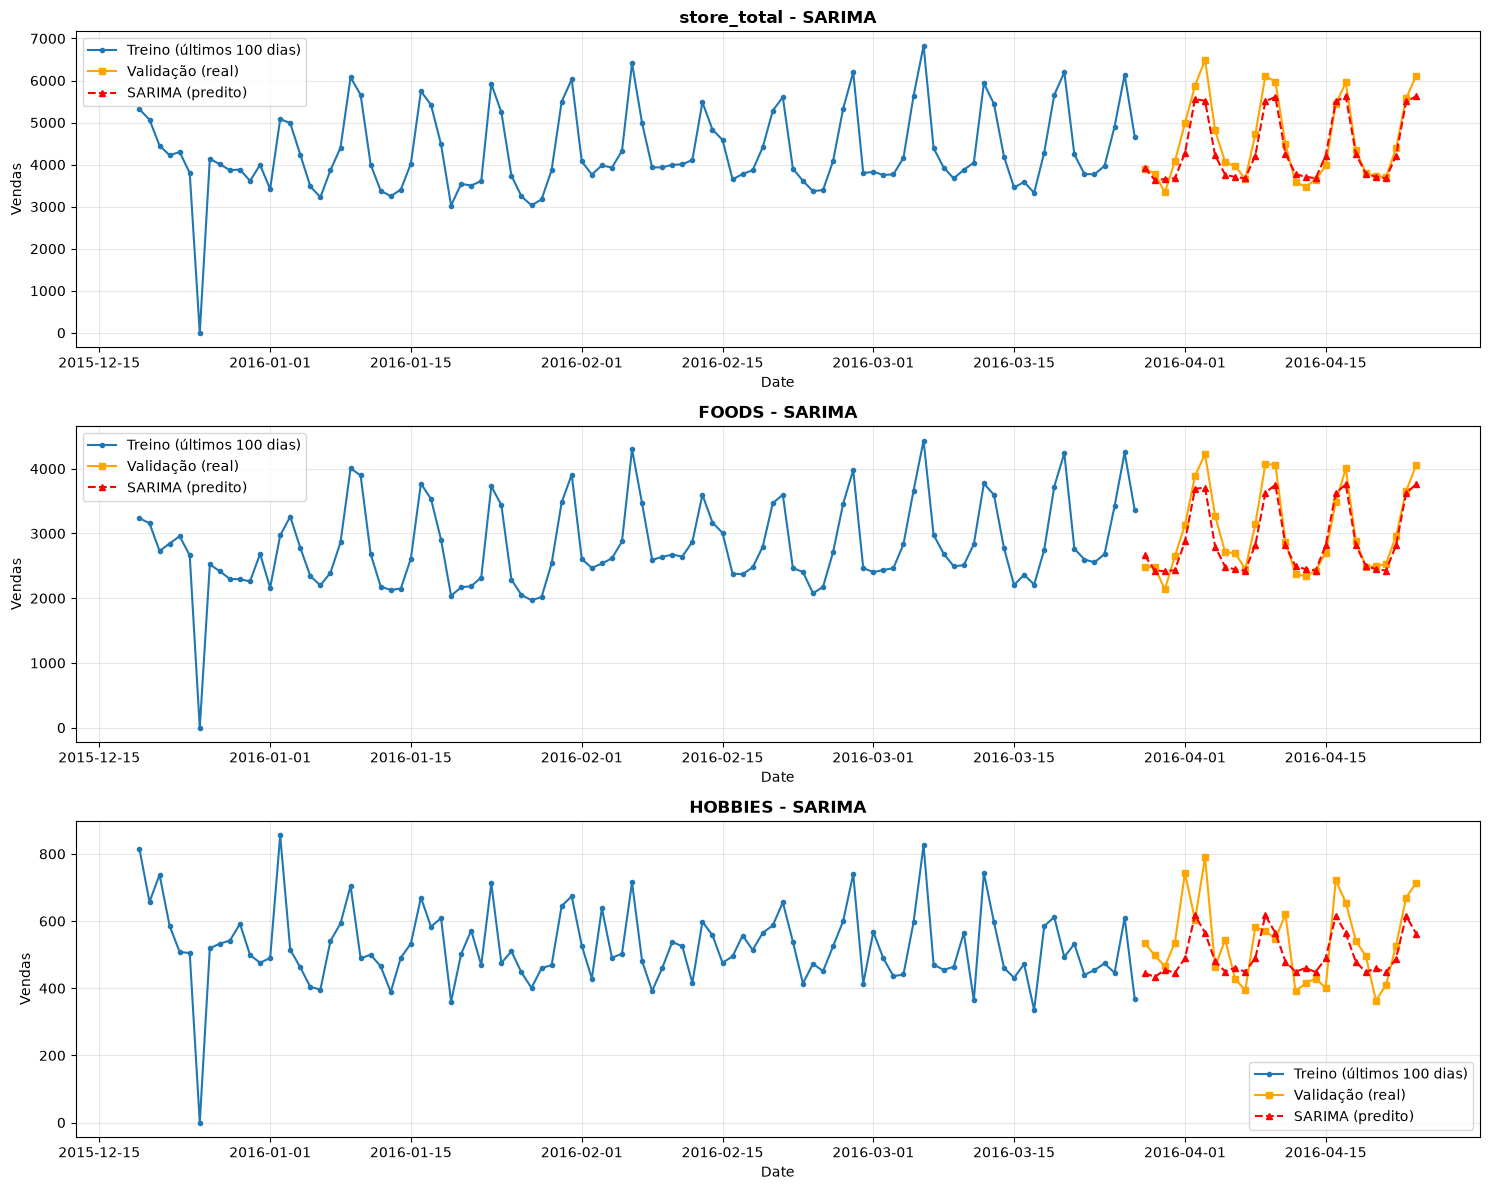

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

for idx, serie_name in enumerate(series_names):
    ax = axes[idx]
    
    # Plot dos últimos 100 dias do treino
    tail_train = min(100, len(df_train))
    ax.plot(df_train["date"].iloc[-tail_train:], 
            df_train[serie_name].iloc[-tail_train:], 
            label="Treino (últimos 100 dias)", marker="o", markersize=3)
    
    # Plot da validação
    ax.plot(df_val["date"], df_val[serie_name], 
            label="Validação (real)", marker="s", markersize=5, color="orange")
    
    # Plot das previsões SARIMA
    ax.plot(df_val["date"], previsoes_sarima[serie_name], 
            label="SARIMA (predito)", marker="^", markersize=5, color="red", linestyle="--")
    
    ax.set_title(f"{serie_name} - SARIMA", fontsize=12, fontweight="bold")
    ax.set_xlabel("Date")
    ax.set_ylabel("Vendas")
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../../docs/previsoes_sarima.png", dpi=150, bbox_inches="tight")
print("\n✓ Gráfico de previsões salvo em docs/previsoes_sarima.png")
plt.show()

## Resumo das ordens identificadas

In [12]:
print("\n" + "="*70)
print("ORDENS SARIMA IDENTIFICADAS (via grid search com AIC)")
print("="*70)

for serie_name in series_names:
    order, seasonal_order = sarima_orders[serie_name]
    results = fitted_models[serie_name]
    print(f"\n{serie_name}:")
    print(f"  Ordem SARIMA: {order}{seasonal_order}")
    print(f"  AIC: {results.aic:.2f}")
    print(f"  Descrição: SARIMA(p={order[0]}, d={order[1]}, q={order[2]})(P={seasonal_order[0]}, D={seasonal_order[1]}, Q={seasonal_order[2]}, m=7)")

print("\n" + "="*70)
print("Previsões salvas no formato CSV (será integrado com baselines)")
print("="*70)


ORDENS SARIMA IDENTIFICADAS (via grid search com AIC)

store_total:
  Ordem SARIMA: (1, 1, 2)(1, 1, 1, 7)
  AIC: 27995.67
  Descrição: SARIMA(p=1, d=1, q=2)(P=1, D=1, Q=1, m=7)

FOODS:
  Ordem SARIMA: (1, 1, 2)(1, 1, 1, 7)
  AIC: 26908.67
  Descrição: SARIMA(p=1, d=1, q=2)(P=1, D=1, Q=1, m=7)

HOBBIES:
  Ordem SARIMA: (1, 1, 2)(0, 1, 1, 7)
  AIC: 21996.09
  Descrição: SARIMA(p=1, d=1, q=2)(P=0, D=1, Q=1, m=7)

Previsões salvas no formato CSV (será integrado com baselines)


## Calculando as Métrica do SARIMA

In [15]:
h = len(df_val)
previsoes_sarima = {}

for serie_name in series_names:
    results = fitted_models[serie_name]

    forecast = np.asarray(
        results.get_forecast(steps=h).predicted_mean
    )

    previsoes_sarima[serie_name] = forecast

    print(
        f"{serie_name}: "
        f"min={forecast.min():.0f}, "
        f"max={forecast.max():.0f}, "
        f"mean={forecast.mean():.0f}"
    )

store_total: min=3633, max=5625, mean=4374
FOODS: min=2418, max=3761, mean=2906
HOBBIES: min=434, max=617, mean=499


In [17]:
metricas_sarima = []

for serie_name in series_names:
    y_train = df_train[serie_name].to_numpy()
    y_val = df_val[serie_name].to_numpy()
    yhat = previsoes_sarima[serie_name]

    # Escala do MASE:
    # MAE in-sample do naive sazonal com período 7
    escala_mase = np.mean(
        np.abs(y_train[7:] - y_train[:-7])
    )

    # Erros na validação
    erro = y_val - yhat

    mae = np.mean(np.abs(erro))
    rmse = np.sqrt(np.mean(erro ** 2))
    mase = mae / escala_mase

    metricas_sarima.append({
        "series": serie_name,
        "modelo": "sarima",
        "mae": mae,
        "rmse": rmse,
        "mase": mase
    })

df_metricas_sarima = pd.DataFrame(metricas_sarima)

display(df_metricas_sarima)

,series,modelo,mae,rmse,mase
0,store_total,sarima,276.295978,363.297381,0.635139
1,FOODS,sarima,186.956692,232.691803,0.546517
2,HOBBIES,sarima,76.445457,95.784893,0.837233


In [18]:
df_metricas_sarima.to_csv(
    "metricas_sarima.csv",
    index=False
)